# 01 · Data exploration — QQQ

**Objective:** Examine QQQ prices, returns, and volatility before choosing predictors.

**Input:** `data/qqq_prices.csv`, a saved snapshot of daily adjusted OHLCV prices from Yahoo Finance (January 2010–September 2026).

**Output:** Exploratory statistics and charts. The saved price snapshot is reused by notebooks 02 and 05.

The notebook loads the committed snapshot by default. To intentionally refresh the historical data, change `REFRESH_DATA` to `True` in the next code section. A vendor refresh may revise historical values and therefore alter downstream results.


## 1. Load the historical price snapshot

Use the saved price file for reproducibility. An optional refresh is available but is **disabled by default** so that restarting and running this notebook doesn't silently overwrite the data used in the research.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
data_dir = project_dir / "data"


In [2]:
prices_path = data_dir / "qqq_prices.csv"
REFRESH_DATA = False

if REFRESH_DATA:
    import yfinance as yf

    refreshed = yf.Ticker("QQQ").history(
        start="2010-01-01",
        end="2026-09-02",  # Exclusive upper bound
        interval="1d",
        auto_adjust=True,
        actions=False,
    )
    if refreshed.empty:
        raise ValueError("QQQ download returned no observations.")
    refreshed.index = pd.to_datetime(refreshed.index)
    if refreshed.index.tz is not None:
        refreshed.index = refreshed.index.tz_localize(None)
    refreshed.index = refreshed.index.normalize()
    refreshed = refreshed[["Open", "High", "Low", "Close", "Volume"]].sort_index()
    refreshed.index.name = "Date"
    data_dir.mkdir(exist_ok=True)
    refreshed.to_csv(prices_path, index_label="Date")
    print("Historical snapshot refreshed intentionally.")

if not prices_path.exists():
    raise FileNotFoundError(
        "Missing data/qqq_prices.csv; supply the committed snapshot or enable REFRESH_DATA."
    )
qqq = pd.read_csv(prices_path, index_col="Date", parse_dates=["Date"])
qqq = qqq[["Open", "High", "Low", "Close", "Volume"]].sort_index()
assert not qqq.index.has_duplicates
assert qqq.index.is_monotonic_increasing
assert not qqq.isna().any().any()

print("Loaded: data/qqq_prices.csv")
print("Rows:", len(qqq))
print("Date range:", qqq.index.min().date(), "to", qqq.index.max().date())
qqq.head()


Loaded: data/qqq_prices.csv
Rows: 4191
Date range: 2010-01-04 to 2026-09-01


,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04,40.126720,40.265297,40.074752,40.204666,62822800
2010-01-05,40.178684,40.273956,39.979480,40.204666,62935600
2010-01-06,40.187348,40.317262,39.901531,39.962158,96033000
2010-01-07,40.022789,40.074757,39.771617,39.988144,77094100
2010-01-08,39.901507,40.317238,39.780253,40.317238,88886600


## 2. Daily returns and descriptive statistics

A close-to-close daily return is `Close_t / Close_(t−1) − 1`. We multiply
by 100, so all reported return and volatility numbers here use **percent**,
not decimal fractions. The first return is missing by construction.


In [3]:
qqq["Daily_Return_Pct"] = qqq["Close"].pct_change() * 100
daily_returns = qqq["Daily_Return_Pct"].dropna()
print(qqq[["Open", "Close", "Daily_Return_Pct"]].head())
daily_returns.describe()


                 Open      Close  Daily_Return_Pct
Date                                              
2010-01-04  40.126720  40.204666               NaN
2010-01-05  40.178684  40.204666          0.000000
2010-01-06  40.187348  39.962158         -0.603184
2010-01-07  40.022789  39.988144          0.065026
2010-01-08  39.901507  40.317238          0.822979


count    4190.000000
mean        0.076932
std         1.301714
min       -11.978780
25%        -0.482204
50%         0.117394
75%         0.742169
max        12.003076
Name: Daily_Return_Pct, dtype: float64

## 3. Price and return behavior

Price shows QQQ's long-run trend; daily returns expose short-run
variability that is hidden by the rising price level.


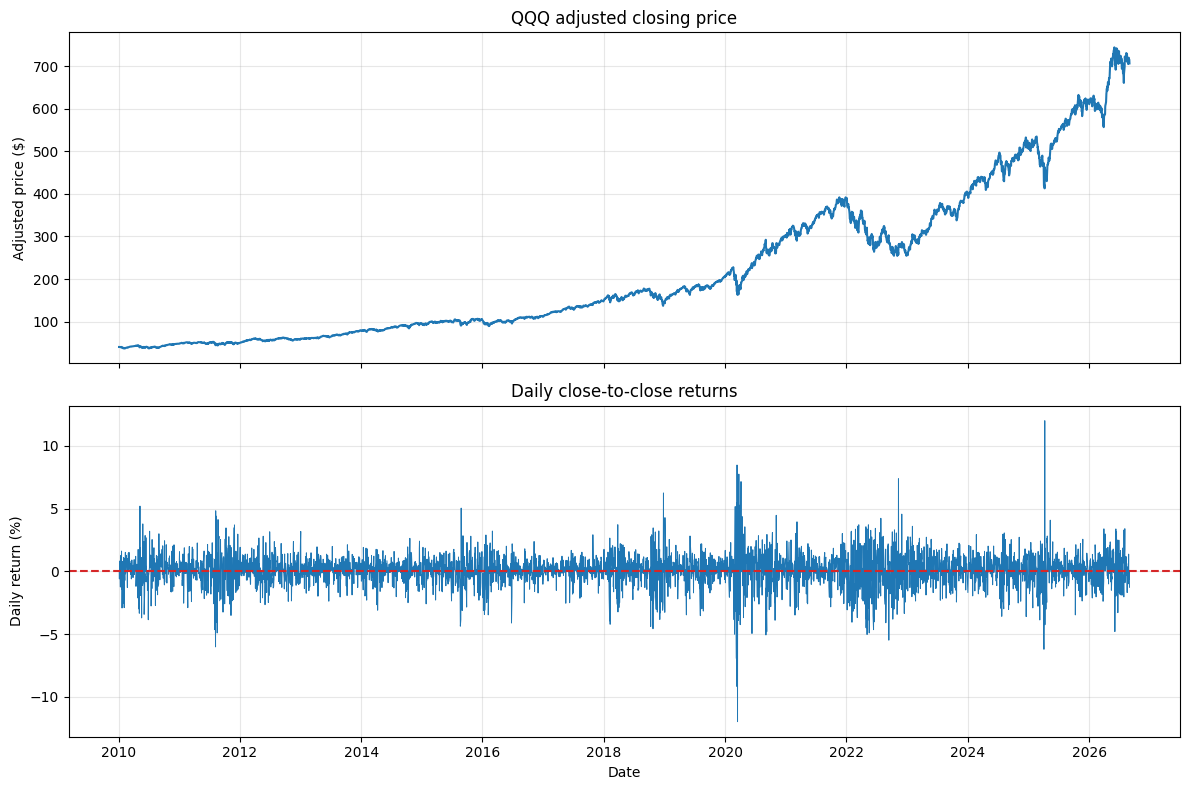

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(qqq.index, qqq["Close"], color="tab:blue")
axes[0].set(title="QQQ adjusted closing price", ylabel="Adjusted price ($)")
axes[1].plot(qqq.index, qqq["Daily_Return_Pct"],
             color="tab:blue", linewidth=0.7)
axes[1].axhline(0, color="tab:red", linestyle="--")
axes[1].set(title="Daily close-to-close returns",
            xlabel="Date", ylabel="Daily return (%)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Return distribution and extreme days

Compare returns with a normal distribution fitted to the sample mean
and standard deviation. This is an exploratory comparison, not an
assumption that financial returns truly follow a normal distribution.
We also count observations more than three sample standard deviations
away from the sample mean.


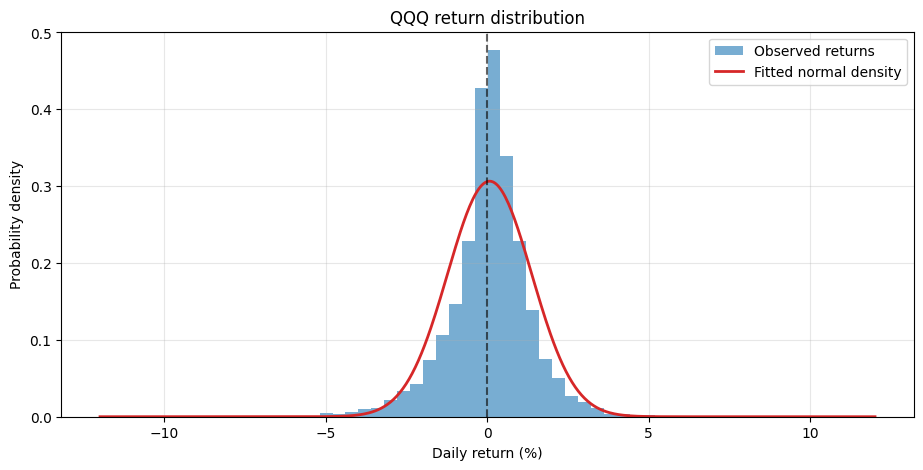

Absolute z-score > 3: 61
Share of days (%): 1.46


In [5]:
mean_return = daily_returns.mean()
std_return = daily_returns.std()
grid = np.linspace(daily_returns.min(), daily_returns.max(), 500)

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(daily_returns, bins=60, density=True,
        color="tab:blue", alpha=0.6, label="Observed returns")
ax.plot(grid, norm.pdf(grid, mean_return, std_return),
        color="tab:red", linewidth=2, label="Fitted normal density")
ax.axvline(0, color="black", linestyle="--", alpha=0.6)
ax.set(title="QQQ return distribution", xlabel="Daily return (%)",
       ylabel="Probability density")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

z_scores = (daily_returns - mean_return) / std_return
print("Absolute z-score > 3:", int((z_scores.abs() > 3).sum()))
print("Share of days (%):", round((z_scores.abs() > 3).mean() * 100, 2))


## 5. Rolling volatility

A trailing 20-trading-day standard deviation describes **recent** daily
return variability. It uses current and past observations only.


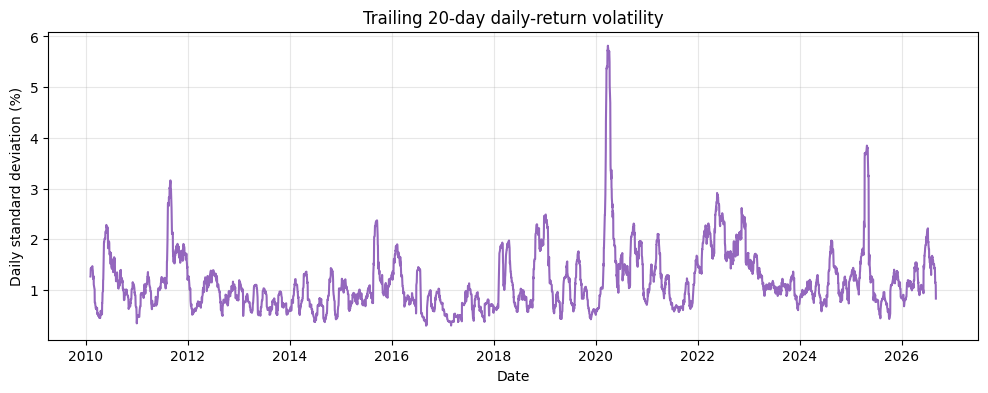

In [6]:
rolling_volatility = qqq["Daily_Return_Pct"].rolling(20).std()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(qqq.index, rolling_volatility, color="tab:purple")
ax.set(title="Trailing 20-day daily-return volatility",
       xlabel="Date", ylabel="Daily standard deviation (%)")
ax.grid(alpha=0.3)
plt.show()


## Takeaway

QQQ daily returns fluctuate substantially despite the long-run price
trend. This motivates exploring short-term momentum, volatility, and
moving-average features in notebook 02. Exploration does not itself
establish predictability; the claim must survive later validation.
